# UFC value betting with fractional Kelly sizing

This notebook evaluates the saved yearly models with a value-betting strategy:

1. Match each fight with its bookmaker odds.
2. Remove the bookmaker margin for market-probability comparison.
3. Calculate expected value using the actual odds.
4. Require a minimum estimated edge.
5. Size positive-EV bets with fractional Kelly, capped as a percentage of bankroll.
6. Stop placing bets after the configured loss limit.

This notebook assumes that the yearly model used for a fight was trained only on fights before that fight's year. It also assumes the odds file contains prices available before the fights; later or closing odds could introduce look-ahead bias.

In [10]:
from pathlib import Path
import re
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data_clean").is_dir() and (candidate / "simulation").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the UFC-Predictions project root.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data_clean" / "w_pre_fight_stats.csv"
ODDS_PATH = PROJECT_ROOT / "data_raw" / "ufc_odds.csv"
MODEL_DIR = PROJECT_ROOT / "simulation" / "models"

INITIAL_BANKROLL = 1_000.0
MIN_PRIOR_FIGHTS = 2
MIN_EXPECTED_VALUE = 0.03  # 3% minimum estimated return per dollar wagered.
KELLY_MULTIPLIER = 0.25  # Quarter Kelly.
MAX_BET_FRACTION = 0.02  # Never risk more than 2% of current bankroll.
LOSS_LIMIT_FRACTION = 1  # Stop when bankroll is 20% below its starting value.
LOSS_LIMIT = INITIAL_BANKROLL * LOSS_LIMIT_FRACTION
LOSS_FLOOR = INITIAL_BANKROLL - LOSS_LIMIT

sys.path.insert(0, str(PROJECT_ROOT / "simulation"))
from train_models import load_eligible_data

print(f"Project root: {PROJECT_ROOT}")
print(f"Initial bankroll: ${INITIAL_BANKROLL:,.2f}")
print(f"Loss floor: ${LOSS_FLOOR:,.2f}")

Project root: e:\Libraries\Documents\GitHub\UFC-Predictions
Initial bankroll: $1,000.00
Loss floor: $0.00


## Load the saved yearly models

In [11]:
MODEL_FILE_PATTERN = re.compile(r"xgb_min_for_(\d{4})\.joblib$")
MODEL_ARTIFACTS = {}

for model_path in sorted(MODEL_DIR.glob("xgb_min_for_*.joblib")):
    match = MODEL_FILE_PATTERN.fullmatch(model_path.name)
    if match:
        MODEL_ARTIFACTS[int(match.group(1))] = joblib.load(model_path)

if not MODEL_ARTIFACTS:
    raise FileNotFoundError(f"No yearly models found in {MODEL_DIR}")

print(f"Loaded models for years: {sorted(MODEL_ARTIFACTS)}")

Loaded models for years: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


## Load eligible fights and match bookmaker odds

The same eligibility rule used during training is applied: both fighters must have at least two prior fights, and only recorded `Red`/`Blue` outcomes with valid dates are retained. Odds are matched using date plus the red and blue fighter names, preserving corner orientation.

In [12]:
def normalize_name(value) -> str:
    return " ".join(str(value).strip().casefold().split())


def american_implied_probability(american_odds):
    odds = pd.to_numeric(american_odds, errors="coerce")
    return np.where(
        odds > 0,
        100.0 / (odds + 100.0),
        np.where(odds < 0, abs(odds) / (abs(odds) + 100.0), np.nan),
    )


def american_decimal_odds(american_odds):
    odds = pd.to_numeric(american_odds, errors="coerce")
    return np.where(
        odds > 0,
        1.0 + odds / 100.0,
        np.where(odds < 0, 1.0 + 100.0 / abs(odds), np.nan),
    )


fights, raw_feature_columns = load_eligible_data(DATA_PATH)
fights["date"] = pd.to_datetime(fights["date"], errors="coerce")
fights["fight_year"] = fights["date"].dt.year
fights["date_key"] = fights["date"].dt.normalize()
fights["red_fighter_key"] = fights["R_fighter"].map(normalize_name)
fights["blue_fighter_key"] = fights["B_fighter"].map(normalize_name)

odds = pd.read_csv(ODDS_PATH)
odds["date"] = pd.to_datetime(odds["Date"], errors="coerce")
odds["date_key"] = odds["date"].dt.normalize()
odds["red_fighter_key"] = odds["RedFighter"].map(normalize_name)
odds["blue_fighter_key"] = odds["BlueFighter"].map(normalize_name)
odds["RedOdds"] = pd.to_numeric(odds["RedOdds"], errors="coerce")
odds["BlueOdds"] = pd.to_numeric(odds["BlueOdds"], errors="coerce")

odds["red_implied_prob"] = american_implied_probability(odds["RedOdds"])
odds["blue_implied_prob"] = american_implied_probability(odds["BlueOdds"])

# If the CSV supplies these columns, verify they agree with the American odds.
if {"RedProbOdds", "BlueProbOdds"}.issubset(odds.columns):
    red_diff = (odds["red_implied_prob"] - pd.to_numeric(odds["RedProbOdds"], errors="coerce")).abs().max()
    blue_diff = (odds["blue_implied_prob"] - pd.to_numeric(odds["BlueProbOdds"], errors="coerce")).abs().max()
    print(f"Maximum Red probability difference: {red_diff:.8f}")
    print(f"Maximum Blue probability difference: {blue_diff:.8f}")

KEY_COLUMNS = ["date_key", "red_fighter_key", "blue_fighter_key"]
if odds.duplicated(KEY_COLUMNS).any():
    raise ValueError("Odds contain duplicate date/red/blue keys.")

odds_for_merge = odds[KEY_COLUMNS + ["RedOdds", "BlueOdds", "red_implied_prob", "blue_implied_prob"]]
matched = fights.merge(odds_for_merge, on=KEY_COLUMNS, how="left", validate="many_to_one")
matched["has_odds"] = matched[["RedOdds", "BlueOdds"]].notna().all(axis=1)
matched = matched[matched["has_odds"] & matched["fight_year"].isin(MODEL_ARTIFACTS)].copy()
matched = matched.sort_values(["date", "fight_id"]).reset_index(drop=True)

print(f"Eligible fights with odds and models: {len(matched):,}")
print(f"Simulation years: {sorted(matched['fight_year'].unique())}")

Maximum Red probability difference: 0.00005000
Maximum Blue probability difference: 0.00005000
Eligible fights with odds and models: 3,562
Simulation years: [np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]


## Reuse each model's saved preprocessing and generate probabilities

In [13]:
def transform_with_saved_preprocessors(data: pd.DataFrame, artifact: dict) -> pd.DataFrame:
    transformed = pd.DataFrame(index=data.index)
    preprocessors = artifact["preprocessors"]

    context = preprocessors.get("context")
    if context is not None:
        context_columns = context["columns"]
        values = data[context_columns].apply(pd.to_numeric, errors="coerce")
        transformed[context_columns] = context["scaler"].transform(context["imputer"].transform(values))

    for suffix, params in preprocessors["paired"].items():
        red = pd.to_numeric(data[params["r_column"]], errors="coerce")
        blue = pd.to_numeric(data[params["b_column"]], errors="coerce")
        red_scaled = (red.fillna(params["median"]) - params["mean"]) / params["std"]
        blue_scaled = (blue.fillna(params["median"]) - params["mean"]) / params["std"]
        transformed[f"DIFF_{suffix}"] = red_scaled - blue_scaled

    model_columns = artifact["model_feature_columns"]
    missing = sorted(set(model_columns) - set(transformed.columns))
    if missing:
        raise ValueError(f"Missing model columns: {missing}")
    return transformed.loc[:, model_columns]


prediction_frames = []
for fight_year, year_fights in matched.groupby("fight_year", sort=True):
    artifact = MODEL_ARTIFACTS[int(fight_year)]
    features = transform_with_saved_preprocessors(year_fights, artifact)
    probability_red = artifact["model"].predict_proba(features)[:, 1]
    year_predictions = year_fights.copy()
    year_predictions["model_probability_red"] = probability_red
    year_predictions["model_probability_blue"] = 1.0 - probability_red
    prediction_frames.append(year_predictions)

predictions = (
    pd.concat(prediction_frames, ignore_index=True)
    .sort_values(["date", "fight_id"])
    .reset_index(drop=True)
)
print(f"Predictions ready: {len(predictions):,}")

Predictions ready: 3,562


## Remove vig, calculate value, and choose bets

The normalized no-vig probabilities describe the market's estimated opinion without the built-in margin. The EV calculation deliberately uses the original decimal odds, because those are the actual prices available to the bettor.

Only the side with the highest EV is considered, and only when its EV is at least `MIN_EXPECTED_VALUE`.

In [14]:
value = predictions.copy()
value["market_probability_total"] = value["red_implied_prob"] + value["blue_implied_prob"]
value["red_no_vig_probability"] = value["red_implied_prob"] / value["market_probability_total"]
value["blue_no_vig_probability"] = value["blue_implied_prob"] / value["market_probability_total"]
value["bookmaker_overround"] = value["market_probability_total"] - 1.0
value["red_decimal_odds"] = american_decimal_odds(value["RedOdds"])
value["blue_decimal_odds"] = american_decimal_odds(value["BlueOdds"])
value["red_expected_value"] = value["model_probability_red"] * value["red_decimal_odds"] - 1.0
value["blue_expected_value"] = value["model_probability_blue"] * value["blue_decimal_odds"] - 1.0

red_is_value = (value["red_expected_value"] >= MIN_EXPECTED_VALUE)
blue_is_value = (value["blue_expected_value"] >= MIN_EXPECTED_VALUE)
red_is_best = red_is_value & (value["red_expected_value"] >= value["blue_expected_value"])
blue_is_best = blue_is_value & (value["blue_expected_value"] > value["red_expected_value"])
value["bet_side"] = np.select([red_is_best, blue_is_best], ["Red", "Blue"], default="No bet")
value["bet_placed"] = value["bet_side"] != "No bet"
value["selected_model_probability"] = np.where(
    value["bet_side"] == "Red", value["model_probability_red"],
    np.where(value["bet_side"] == "Blue", value["model_probability_blue"], np.nan),
)
value["selected_decimal_odds"] = np.where(
    value["bet_side"] == "Red", value["red_decimal_odds"],
    np.where(value["bet_side"] == "Blue", value["blue_decimal_odds"], np.nan),
)
value["selected_expected_value"] = np.where(
    value["bet_side"] == "Red", value["red_expected_value"],
    np.where(value["bet_side"] == "Blue", value["blue_expected_value"], 0.0),
)

value[[
    "date", "R_fighter", "B_fighter", "model_probability_red",
    "red_no_vig_probability", "blue_no_vig_probability",
    "red_expected_value", "blue_expected_value", "bet_side",
]].head(20)

,date,R_fighter,B_fighter,model_probability_red,red_no_vig_probability,blue_no_vig_probability,red_expected_value,blue_expected_value,bet_side
0,2010-03-21,Junior Dos Santos,Gabriel Gonzaga,0.468572,0.702128,0.297872,-0.343999,0.753712,Blue
1,2010-03-21,Alessio Sakara,James Irvin,0.609722,0.521739,0.478261,0.117824,-0.219445,Red
2,2010-03-21,Brandon Vera,Jon Jones,0.365458,0.311555,0.688445,0.151193,-0.095440,Red
3,2010-03-21,Cheick Kongo,Paul Buentello,0.587553,0.762888,0.237112,-0.242142,0.711654,Blue
4,2010-03-21,Eliot Marshall,Vladimir Matyushenko,0.275019,0.395966,0.604034,-0.326204,0.164364,Blue
5,2010-03-21,Clay Guida,Shannon Gugerty,0.745192,0.778441,0.221559,-0.077381,0.108414,Blue
6,2010-03-21,Eric Schafer,Jason Brilz,0.570542,0.403727,0.596273,0.369301,-0.302131,Red
7,2010-03-27,Frank Mir,Shane Carwin,0.652367,0.590164,0.409836,0.087279,-0.165682,Red
8,2010-03-27,Ben Saunders,Jon Fitch,0.374477,0.248720,0.751280,0.479183,-0.182008,Red
9,2010-03-27,Georges St-Pierre,Dan Hardy,0.831446,0.849246,0.150754,-0.040639,0.095600,Blue


## Calculate fractional Kelly size and simulate the bankroll

Kelly sizing uses the model probability and actual decimal odds. The wager is based on the current bankroll immediately before each fight, is reduced to quarter Kelly, and is capped at `MAX_BET_FRACTION`. No bet is placed after the loss floor is reached.

In [15]:
def kelly_fraction(model_probability: float, decimal_odds: float) -> float:
    b = decimal_odds - 1.0
    if b <= 0 or not np.isfinite(model_probability) or not np.isfinite(decimal_odds):
        return 0.0
    q = 1.0 - model_probability
    return max(0.0, (b * model_probability - q) / b)


value["full_kelly_fraction"] = 0.0
selected = value["bet_placed"]
value.loc[selected, "full_kelly_fraction"] = [
    kelly_fraction(probability, decimal_odds)
    for probability, decimal_odds in zip(
        value.loc[selected, "selected_model_probability"],
        value.loc[selected, "selected_decimal_odds"],
    )
]
value["quarter_kelly_fraction"] = value["full_kelly_fraction"] * KELLY_MULTIPLIER
value["requested_bet_fraction"] = np.minimum(value["quarter_kelly_fraction"], MAX_BET_FRACTION)

bankroll = INITIAL_BANKROLL
simulation_rows = []

for _, row in value.iterrows():
    bankroll_before = bankroll
    loss_limit_reached = bankroll_before <= LOSS_FLOOR
    can_bet = bool(row["bet_placed"]) and not loss_limit_reached and bankroll_before > 0
    bet_fraction = float(row["requested_bet_fraction"]) if can_bet else 0.0
    bet_amount = bankroll_before * bet_fraction
    bet_won = bool(can_bet and row["Winner"] == row["bet_side"])

    if not can_bet:
        net_profit = 0.0
    elif bet_won:
        net_profit = bet_amount * (float(row["selected_decimal_odds"]) - 1.0)
    else:
        net_profit = -bet_amount

    bankroll = bankroll_before + net_profit
    simulation_rows.append(
        {
            "bankroll_before": bankroll_before,
            "bet_fraction": bet_fraction,
            "bet_amount": bet_amount,
            "bet_won": bet_won,
            "net_profit": net_profit,
            "bankroll_after": bankroll,
            "loss_limit_reached_before_fight": loss_limit_reached,
            "bet_executed": can_bet,
        }
    )

simulation = pd.concat([value.reset_index(drop=True), pd.DataFrame(simulation_rows)], axis=1)
simulation["bet_number"] = simulation["bet_executed"].cumsum()

assert abs(kelly_fraction(0.20, 6.50) - 0.05454545454545454) < 1e-12
simulation[[
    "date", "R_fighter", "B_fighter", "bet_side",
    "selected_expected_value", "full_kelly_fraction",
    "bet_fraction", "bet_amount", "bet_won",
    "net_profit", "bankroll_after",
]].head(20)

,date,R_fighter,B_fighter,bet_side,selected_expected_value,full_kelly_fraction,bet_fraction,bet_amount,bet_won,net_profit,bankroll_after
0,2010-03-21,Junior Dos Santos,Gabriel Gonzaga,Blue,0.753712,0.327701,0.020000,20.000000,False,-20.000000,980.000000
1,2010-03-21,Alessio Sakara,James Irvin,Red,0.117824,0.141389,0.020000,19.600000,True,16.333333,996.333333
2,2010-03-21,Brandon Vera,Jon Jones,Red,0.151193,0.070323,0.017581,17.516165,False,-17.516165,978.817168
3,2010-03-21,Cheick Kongo,Paul Buentello,Blue,0.711654,0.225922,0.020000,19.576343,False,-19.576343,959.240825
4,2010-03-21,Eliot Marshall,Vladimir Matyushenko,Blue,0.164364,0.271200,0.020000,19.184817,True,11.627162,970.867987
5,2010-03-21,Clay Guida,Shannon Gugerty,Blue,0.108414,0.032362,0.008091,7.854868,False,-7.854868,963.013118
6,2010-03-21,Eric Schafer,Jason Brilz,Red,0.369301,0.263787,0.020000,19.260262,False,-19.260262,943.752856
7,2010-03-27,Frank Mir,Shane Carwin,Red,0.087279,0.130919,0.020000,18.875057,False,-18.875057,924.877799
8,2010-03-27,Ben Saunders,Jon Fitch,Red,0.479183,0.162435,0.020000,18.497556,False,-18.497556,906.380243
9,2010-03-27,Georges St-Pierre,Dan Hardy,Blue,0.095600,0.017382,0.004345,3.938614,False,-3.938614,902.441629


## Results and bankroll plot

,value
starting_bankroll,1000.000000
final_bankroll,77.291931
total_return,-0.922708
total_fights_considered,3562.000000
bets_executed,3044.000000
no_bet_fights,518.000000
wins,1194.000000
losses,1850.000000
win_rate_on_bets,0.392247
total_staked,49086.264242


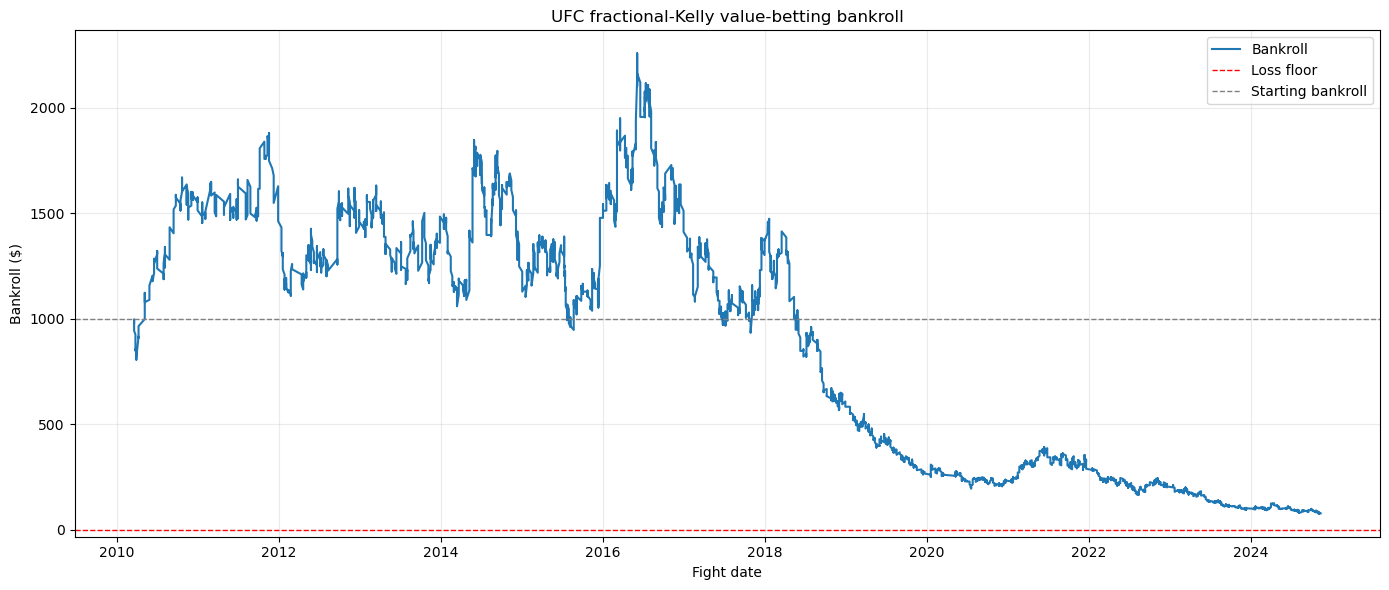

In [16]:
bets = simulation[simulation["bet_executed"]]
bet_count = len(bets)
wins = int(bets["bet_won"].sum())
total_staked = bets["bet_amount"].sum()
peak = simulation["bankroll_after"].cummax()
drawdown = simulation["bankroll_after"] - peak

summary = pd.Series(
    {
        "starting_bankroll": INITIAL_BANKROLL,
        "final_bankroll": simulation["bankroll_after"].iloc[-1],
        "total_return": simulation["bankroll_after"].iloc[-1] / INITIAL_BANKROLL - 1.0,
        "total_fights_considered": len(simulation),
        "bets_executed": bet_count,
        "no_bet_fights": int((~simulation["bet_executed"]).sum()),
        "wins": wins,
        "losses": bet_count - wins,
        "win_rate_on_bets": wins / bet_count if bet_count else np.nan,
        "total_staked": total_staked,
        "maximum_drawdown": drawdown.min(),
        "loss_floor": LOSS_FLOOR,
        "minimum_observed_bankroll": simulation["bankroll_after"].min(),
        "minimum_ev_threshold": MIN_EXPECTED_VALUE,
        "kelly_multiplier": KELLY_MULTIPLIER,
        "maximum_bet_fraction": MAX_BET_FRACTION,
    },
    name="value",
)
display(summary.to_frame())

plt.figure(figsize=(14, 6))
plt.plot(simulation["date"], simulation["bankroll_after"], linewidth=1.5, label="Bankroll")
plt.axhline(LOSS_FLOOR, color="red", linestyle="--", linewidth=1, label="Loss floor")
plt.axhline(INITIAL_BANKROLL, color="gray", linestyle="--", linewidth=1, label="Starting bankroll")
plt.title("UFC fractional-Kelly value-betting bankroll")
plt.xlabel("Fight date")
plt.ylabel("Bankroll ($)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
simulation[[
    "bet_number", "date", "fight_id", "R_fighter", "B_fighter",
    "model_probability_red", "red_no_vig_probability",
    "blue_no_vig_probability", "red_expected_value",
    "blue_expected_value", "bet_side", "selected_decimal_odds",
    "full_kelly_fraction", "bet_fraction", "bet_amount",
    "Winner", "bet_won", "net_profit", "bankroll_after",
]].tail(5)

,bet_number,date,fight_id,R_fighter,B_fighter,model_probability_red,red_no_vig_probability,blue_no_vig_probability,red_expected_value,blue_expected_value,bet_side,selected_decimal_odds,full_kelly_fraction,bet_fraction,bet_amount,Winner,bet_won,net_profit,bankroll_after
3557,3040,2024-11-02,876,Caio Machado,Brendson Ribeiro,0.521891,0.630940,0.369060,-0.206290,0.243082,Blue,2.60,0.151926,0.020000,1.514699,Blue,True,2.423519,78.158482
3558,3041,2024-11-02,877,Marc-Andre Barriault,Dustin Stoltzfus,0.351235,0.700162,0.299838,-0.518678,1.076048,Blue,3.20,0.489113,0.020000,1.563170,Blue,True,3.438973,81.597456
3559,3042,2024-11-02,879,Mike Malott,Trevin Giles,0.473860,0.757188,0.242812,-0.399778,1.078255,Blue,3.95,0.365510,0.020000,1.631949,Red,False,-1.631949,79.965506
3560,3043,2024-11-09,862,Neil Magny,Carlos Prates,0.332608,0.147541,0.852459,1.161952,-0.249184,Red,6.50,0.211264,0.020000,1.599310,Blue,False,-1.599310,78.366196
3561,3044,2024-11-09,863,Luana Pinheiro,Gillian Robertson,0.260304,0.208638,0.791362,0.197399,-0.102922,Red,4.60,0.054833,0.013708,1.074266,Blue,False,-1.074266,77.291931


## Worst individual betting losses

In [ ]:
worst_losses = (
    simulation[
        simulation["bet_executed"]
        & ~simulation["bet_won"]
    ]
    .assign(loss_amount=lambda frame: -frame["net_profit"])
    .sort_values(["loss_amount", "date"], ascending=[False, True])
    .loc[:, [
        "bet_number", "date", "fight_id", "R_fighter", "B_fighter",
        "bet_side", "Winner", "selected_decimal_odds",
        "model_probability_red", "selected_model_probability",
        "selected_expected_value", "bet_fraction", "bet_amount",
        "loss_amount", "bankroll_before", "bankroll_after",
    ]]
)


print(f"Total losing bets: {len(worst_losses):,}")
print(f"Total amount lost on losing bets: ${worst_losses['loss_amount'].sum():,.2f}")
worst_losses.head(5)


Total losing bets: 1,850
Total amount lost on losing bets: $29,686.78


,bet_number,date,fight_id,R_fighter,B_fighter,bet_side,Winner,selected_decimal_odds,model_probability_red,selected_model_probability,selected_expected_value,bet_fraction,bet_amount,loss_amount,bankroll_before,bankroll_after
1200,1087,2016-06-04,5079,Dominick Cruz,Urijah Faber,Blue,Red,4.15,0.672493,0.327507,0.359153,0.02,45.176811,45.176811,2258.840570,2213.663759
1203,1089,2016-06-04,5083,Brian Ortega,Clay Guida,Blue,Red,2.95,0.517942,0.482058,0.422070,0.02,43.799092,43.799092,2189.954616,2146.155524
1207,1092,2016-06-18,5065,Donald Cerrone,Patrick Cote,Blue,Red,2.50,0.521397,0.478603,0.196506,0.02,43.284523,43.284523,2164.226153,2120.941630
1204,1090,2016-06-04,5084,Beneil Dariush,James Vick,Blue,Red,2.20,0.352621,0.647379,0.424233,0.02,42.923110,42.923110,2146.155524,2103.232413
1208,1093,2016-06-18,5066,Steve Bosse,Sean O'Connell,Blue,Red,2.15,0.472608,0.527392,0.133892,0.02,42.418833,42.418833,2120.941630,2078.522798
